# Import Data:

Device setting:

In [ ]:
import torch

device = (
    "cuda" if torch.cuda.is_available() 
    else "mps" if torch.backends.mps.is_available() 
    else "cpu"
)
device

In [26]:
from datasets import load_dataset
# Mode streaming at True:
voxpopuli_croatian = load_dataset("facebook/voxpopuli", name = "fr", split="train", streaming=True)

Explore Dataset f training:

In [27]:
first_data = next(iter(voxpopuli_croatian))

first_data

{'audio_id': '20200212-0900-PLENARY-fr_20200212-18:11:25_1',
 'language': 2,
 'audio': <datasets.features._torchcodec.AudioDecoder at 0x2535f5086d0>,
 'raw_text': 'Notre délégation défendra la lutte contre les écarts salariaux à travail égal, contre les cyberviolences, les mariages forcés et les mutilations génitales.',
 'normalized_text': 'notre délégation défendra la lutte contre les écarts salariaux à travail égal contre les cyberviolences les mariages forcés et les mutilations génitales.',
 'gender': 'female',
 'speaker_id': '182995',
 'is_gold_transcript': True,
 'accent': 'None'}

In [28]:
few_data = voxpopuli_croatian.take(3)


for data in few_data:
    print(data["normalized_text"])


notre délégation défendra la lutte contre les écarts salariaux à travail égal contre les cyberviolences les mariages forcés et les mutilations génitales.
en deux mille quinze déjà l'arabie saoudite avait été élue à la commission des droits de l'homme et avait dans la foulée exécuté cent cinquante trois personnes contre vingt six en.
cette régulation concerne les états et leurs économies mais évidemment les principaux acteurs économiques sont les entreprises et en particulier les entreprises multinationales qui sont les principales actrices du commerce mondial.


Data is about: GeoPolitics


# Waveshow & Spectrogram: 

In [29]:
first_data["audio"]["sampling_rate"]


16000

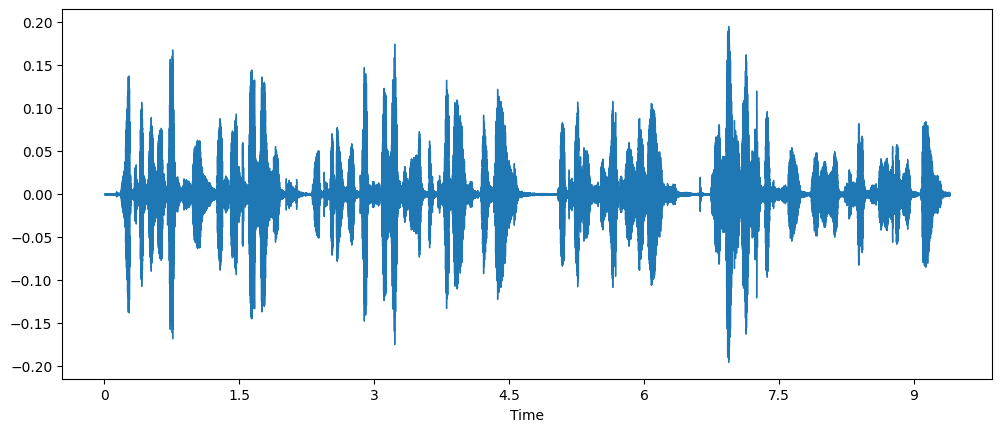

In [30]:
import librosa
import matplotlib.pyplot as plt

# Waveshow:
plt.figure().set_figwidth(12)
librosa.display.waveshow(first_data["audio"]["array"], sr=first_data["audio"]["sampling_rate"])

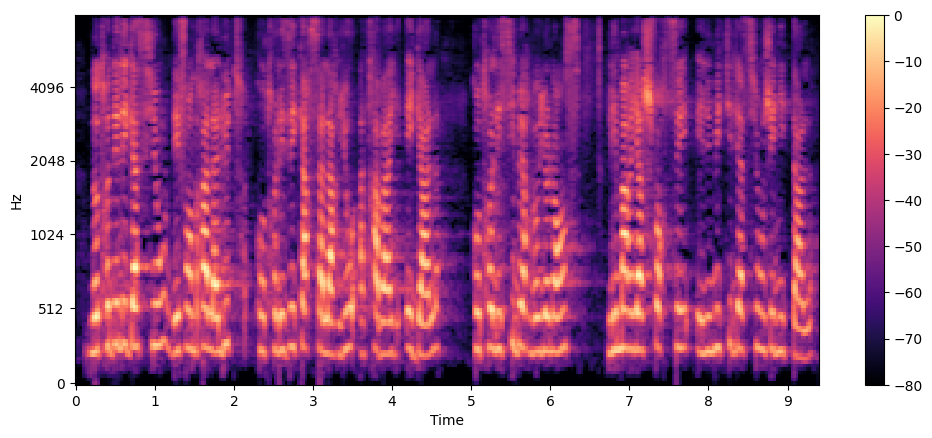

In [31]:
import numpy as np

# Spectrogram:
S = librosa.feature.melspectrogram(y= first_data["audio"]["array"], sr= first_data["audio"]["sampling_rate"], n_mels=128, fmax= 8000)
S_dB = librosa.power_to_db(S, ref=np. max ) 

plt.figure().set_figwidth( 12 ) 
librosa.display.specshow(S_dB, x_axis= "time" , y_axis= "mel" , sr= first_data["audio"]["sampling_rate"], fmax= 8000 ) 
plt.colorbar()

plt.show()


In [33]:
from transformers import pipeline

pipe = pipeline("automatic-speech-recognition", model="bofenghuang/whisper-large-v2-french", device="cpu")

Loading weights: 100%|██████████| 1259/1259 [00:00<00:00, 18033.39it/s]


In [ ]:
pipe(first_data["audio"])

[transformers] Passing `generation_config` together with generation-related arguments=({'suppress_tokens', 'begin_suppress_tokens'}) is deprecated and will be removed in future versions. Please pass either a `generation_config` object OR all generation parameters explicitly, but not both.
